# Comprehensive Exploratory Data Analysis (EDA) Report
## Telco Customer Churn Prediction Dataset

This notebook provides a detailed analysis of the customer churn dataset, including data understanding, visualization, and key insights for business decision-making.

## 1. Import Libraries and Load Data

In [124]:
# Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Set elegant color palette and style for professional reports
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 9

# Professional color palette
colors_professional = ['#2E86AB', '#A23B72', '#F18F01', '#C73E1D', '#6A994E', '#577590']
sns.set_palette(colors_professional)

# Configure display options
pd.set_option('display.max_columns', None)

In [125]:
# Load the dataset
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
print(f"Dataset shape: {df.shape}")
print(f"Dataset loaded successfully with {df.shape[0]} rows and {df.shape[1]} columns")

Dataset shape: (7043, 21)
Dataset loaded successfully with 7043 rows and 21 columns


## 2. Dataset Overview and Basic Information

In [126]:
# Display basic information about the dataset
print("=== DATASET OVERVIEW ===")
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")
print(f"\nMemory usage: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

print("\n=== COLUMN INFORMATION ===")
df.info()

=== DATASET OVERVIEW ===
Number of rows: 7043
Number of columns: 21

Memory usage: 6.82 MB

=== COLUMN INFORMATION ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies  

In [127]:
# Display first few rows
print("=== FIRST 5 ROWS ===")
df.head()

=== FIRST 5 ROWS ===


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [128]:
# Check for missing values
print("=== MISSING VALUES ANALYSIS ===")
missing_values = df.isnull().sum()
missing_percentage = (missing_values / len(df)) * 100

missing_df = pd.DataFrame({
    'Missing Count': missing_values,
    'Missing Percentage': missing_percentage
})

print(missing_df[missing_df['Missing Count'] > 0])
if missing_df['Missing Count'].sum() == 0:
    print("✅ No missing values found in the dataset!")

=== MISSING VALUES ANALYSIS ===
Empty DataFrame
Columns: [Missing Count, Missing Percentage]
Index: []
✅ No missing values found in the dataset!


In [129]:
# Data preprocessing - handle TotalCharges column
print("=== DATA PREPROCESSING ===")

# Check for empty strings in TotalCharges
empty_total_charges = len(df[df["TotalCharges"] == " "])
print(f"Empty strings in TotalCharges: {empty_total_charges}")

if empty_total_charges > 0:
    # Replace empty strings with 0.0
    df["TotalCharges"] = df["TotalCharges"].replace({" ": "0.0"})
    print("✅ Empty strings replaced with 0.0")

# Convert TotalCharges to float
df["TotalCharges"] = df["TotalCharges"].astype(float)
print("✅ TotalCharges converted to float datatype")

# Drop customerID as it's not needed for analysis
if 'customerID' in df.columns:
    df = df.drop(columns=["customerID"])
    print("✅ CustomerID column dropped")

print(f"\nFinal dataset shape: {df.shape}")

=== DATA PREPROCESSING ===
Empty strings in TotalCharges: 11
✅ Empty strings replaced with 0.0
✅ TotalCharges converted to float datatype
✅ CustomerID column dropped

Final dataset shape: (7043, 20)


## 3. Target Variable Analysis

=== TARGET VARIABLE ANALYSIS ===
Churn Distribution:
  No: 5174 (73.5%)
  Yes: 1869 (26.5%)


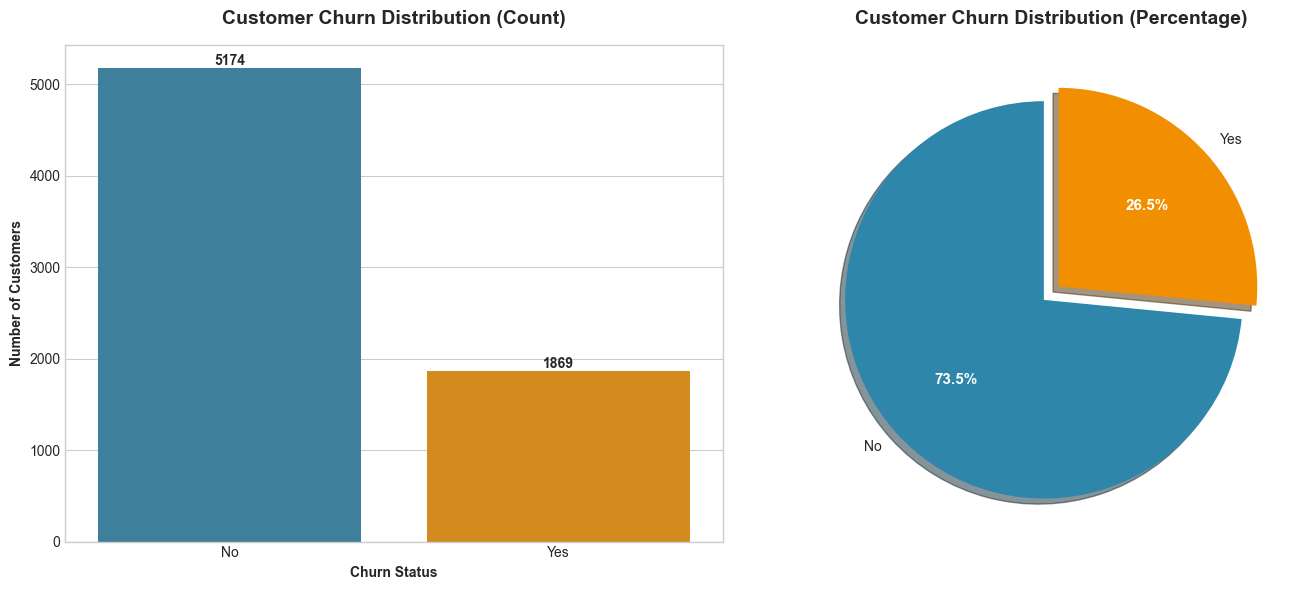


Class Imbalance Ratio: 0.361
Class distribution is reasonably balanced


In [130]:
# Analyze the target variable (Churn)
print("=== TARGET VARIABLE ANALYSIS ===")

churn_counts = df['Churn'].value_counts()
churn_percentage = df['Churn'].value_counts(normalize=True) * 100

print("Churn Distribution:")
for value, count in churn_counts.items():
    percentage = churn_percentage[value]
    print(f"  {value}: {count} ({percentage:.1f}%)")

# Visualize target variable distribution with elegant colors
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Professional color scheme
colors_churn = ['#2E86AB', '#F18F01']  # Blue for No, Orange for Yes

# Count plot
sns.countplot(data=df, x='Churn', ax=ax1, palette=colors_churn)
ax1.set_title('Customer Churn Distribution (Count)', fontsize=14, fontweight='bold', pad=15)
ax1.set_ylabel('Number of Customers', fontweight='bold')
ax1.set_xlabel('Churn Status', fontweight='bold')

# Add value labels on bars
for container in ax1.containers:
    ax1.bar_label(container, fmt='%d', fontweight='bold')

# Pie chart
wedges, texts, autotexts = ax2.pie(churn_counts.values, 
                                   labels=churn_counts.index, 
                                   autopct='%1.1f%%', 
                                   colors=colors_churn,
                                   startangle=90,
                                   explode=(0.05, 0.05),
                                   shadow=True)
ax2.set_title('Customer Churn Distribution (Percentage)', fontsize=14, fontweight='bold', pad=15)

# Style the pie chart text
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontweight('bold')
    autotext.set_fontsize(11)

plt.tight_layout()
plt.show()

# Class imbalance assessment
imbalance_ratio = churn_counts.min() / churn_counts.max()
print(f"\nClass Imbalance Ratio: {imbalance_ratio:.3f}")
if imbalance_ratio < 0.3:
    print("Significant class imbalance detected - consider using SMOTE or other balancing techniques")
else:
    print("Class distribution is reasonably balanced")

## 4. Numerical Features Analysis

In [131]:
# Identify numerical columns
numerical_columns = ['tenure', 'MonthlyCharges', 'TotalCharges']
print(f"Numerical columns: {numerical_columns}")

# Statistical summary
print("\n=== STATISTICAL SUMMARY ===")
print(df[numerical_columns].describe())

Numerical columns: ['tenure', 'MonthlyCharges', 'TotalCharges']

=== STATISTICAL SUMMARY ===
            tenure  MonthlyCharges  TotalCharges
count  7043.000000     7043.000000   7043.000000
mean     32.371149       64.761692   2279.734304
std      24.559481       30.090047   2266.794470
min       0.000000       18.250000      0.000000
25%       9.000000       35.500000    398.550000
50%      29.000000       70.350000   1394.550000
75%      55.000000       89.850000   3786.600000
max      72.000000      118.750000   8684.800000
            tenure  MonthlyCharges  TotalCharges
count  7043.000000     7043.000000   7043.000000
mean     32.371149       64.761692   2279.734304
std      24.559481       30.090047   2266.794470
min       0.000000       18.250000      0.000000
25%       9.000000       35.500000    398.550000
50%      29.000000       70.350000   1394.550000
75%      55.000000       89.850000   3786.600000
max      72.000000      118.750000   8684.800000


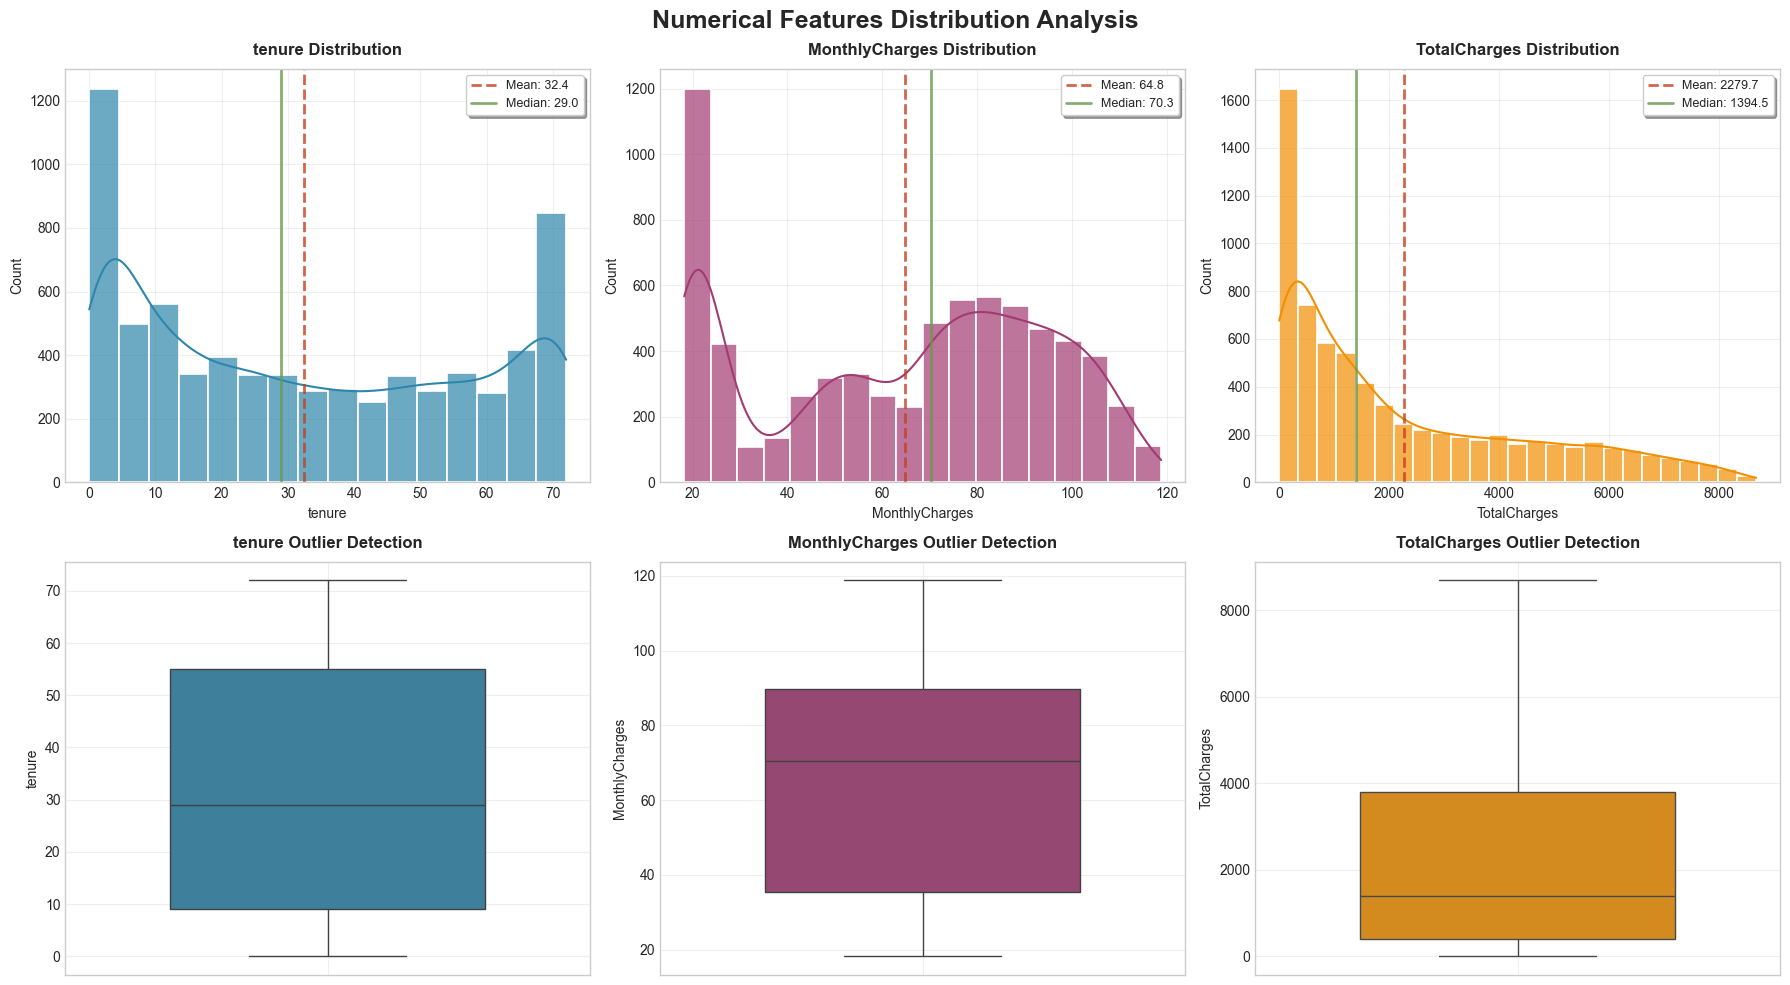

KEY STATISTICS FOR REPORT:

tenure:
  Mean: 32.37
  Median: 29.00
  Std Dev: 24.56
  Skewness: 0.240 (Symmetric)

MonthlyCharges:
  Mean: 64.76
  Median: 70.35
  Std Dev: 30.09
  Skewness: -0.221 (Symmetric)

TotalCharges:
  Mean: 2279.73
  Median: 1394.55
  Std Dev: 2266.79
  Skewness: 0.963 (Right-skewed)


In [132]:
# Essential distribution plots for report with elegant styling
def plot_numerical_distribution_for_report(dataframe, features):
    """
    Essential distribution plots for report with professional styling
    """
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    fig.suptitle('Numerical Features Distribution Analysis', fontsize=18, fontweight='bold', y=0.98)
    
    # Professional colors for different features
    feature_colors = ['#2E86AB', '#A23B72', '#F18F01']
    
    for i, feature in enumerate(features):
        row = i // 3
        col = i % 3
        color = feature_colors[i]
        
        # Histogram with KDE
        sns.histplot(dataframe[feature], kde=True, ax=axes[row, col], 
                    color=color, alpha=0.7, edgecolor='white', linewidth=1.2)
        axes[row, col].set_title(f'{feature} Distribution', fontweight='bold', fontsize=12, pad=10)
        
        # Add mean and median lines with elegant styling
        mean_val = dataframe[feature].mean()
        median_val = dataframe[feature].median()
        axes[row, col].axvline(mean_val, color='#C73E1D', linestyle='--', alpha=0.8, 
                              linewidth=2, label=f'Mean: {mean_val:.1f}')
        axes[row, col].axvline(median_val, color='#6A994E', linestyle='-', alpha=0.8, 
                              linewidth=2, label=f'Median: {median_val:.1f}')
        axes[row, col].legend(frameon=True, fancybox=True, shadow=True)
        axes[row, col].grid(True, alpha=0.3)
    
    # Box plots for outlier detection with elegant styling
    for i, feature in enumerate(features):
        row = 1
        col = i
        if col < 3:
            # Clear the second row and create box plots
            axes[row, col].clear()
            box_plot = sns.boxplot(y=dataframe[feature], ax=axes[row, col], 
                                  color=feature_colors[i], width=0.6)
            axes[row, col].set_title(f'{feature} Outlier Detection', fontweight='bold', fontsize=12, pad=10)
            axes[row, col].grid(True, alpha=0.3)
            
            # Style the box plot
            for patch in box_plot.artists:
                patch.set_facecolor(feature_colors[i])
                patch.set_alpha(0.7)
                patch.set_edgecolor('black')
                patch.set_linewidth(1.2)
    
    plt.tight_layout()
    plt.show()
    
    # Print key statistics for report
    print("KEY STATISTICS FOR REPORT:")
    for i, feature in enumerate(features):
        print(f"\n{feature}:")
        print(f"  Mean: {dataframe[feature].mean():.2f}")
        print(f"  Median: {dataframe[feature].median():.2f}")
        print(f"  Std Dev: {dataframe[feature].std():.2f}")
        skewness = dataframe[feature].skew()
        print(f"  Skewness: {skewness:.3f} ({'Right-skewed' if skewness > 0.5 else 'Left-skewed' if skewness < -0.5 else 'Symmetric'})")

plot_numerical_distribution_for_report(df, numerical_columns)

=== CORRELATION ANALYSIS ===


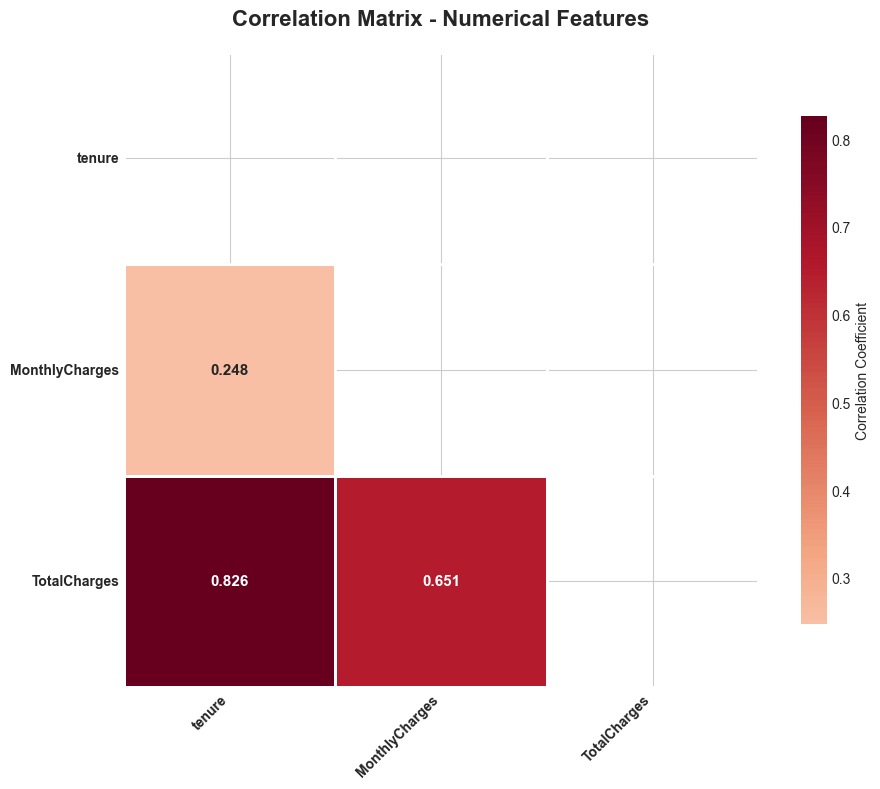


KEY CORRELATION INSIGHTS:
   tenure <-> TotalCharges: Strong positive correlation (0.826)
   MonthlyCharges <-> TotalCharges: Moderate positive correlation (0.651)


In [133]:
# ESSENTIAL GRAPH 2: Correlation Matrix with elegant styling
print("=== CORRELATION ANALYSIS ===")

# Calculate correlation matrix
correlation_matrix = df[numerical_columns].corr()

# Create elegant correlation heatmap for report
plt.figure(figsize=(10, 8))

# Professional diverging colormap
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))
sns.heatmap(correlation_matrix, 
            mask=mask,
            annot=True, 
            cmap='RdBu_r', 
            center=0,
            fmt='.3f',
            square=True,
            linewidths=0.8,
            cbar_kws={'label': 'Correlation Coefficient', 'shrink': 0.8},
            annot_kws={'fontsize': 11, 'fontweight': 'bold'})

plt.title('Correlation Matrix - Numerical Features', fontsize=16, fontweight='bold', pad=20)
plt.xticks(rotation=45, ha='right', fontweight='bold')
plt.yticks(rotation=0, fontweight='bold')
plt.tight_layout()
plt.show()

# Key insights for report
print("\nKEY CORRELATION INSIGHTS:")
for i in range(len(numerical_columns)):
    for j in range(i+1, len(numerical_columns)):
        corr_value = correlation_matrix.iloc[i, j]
        feature1, feature2 = numerical_columns[i], numerical_columns[j]
        
        if abs(corr_value) > 0.5:
            strength = "Strong" if abs(corr_value) > 0.7 else "Moderate"
            direction = "positive" if corr_value > 0 else "negative"
            print(f"   {feature1} <-> {feature2}: {strength} {direction} correlation ({corr_value:.3f})")

## 5. Numerical Features vs Churn Analysis

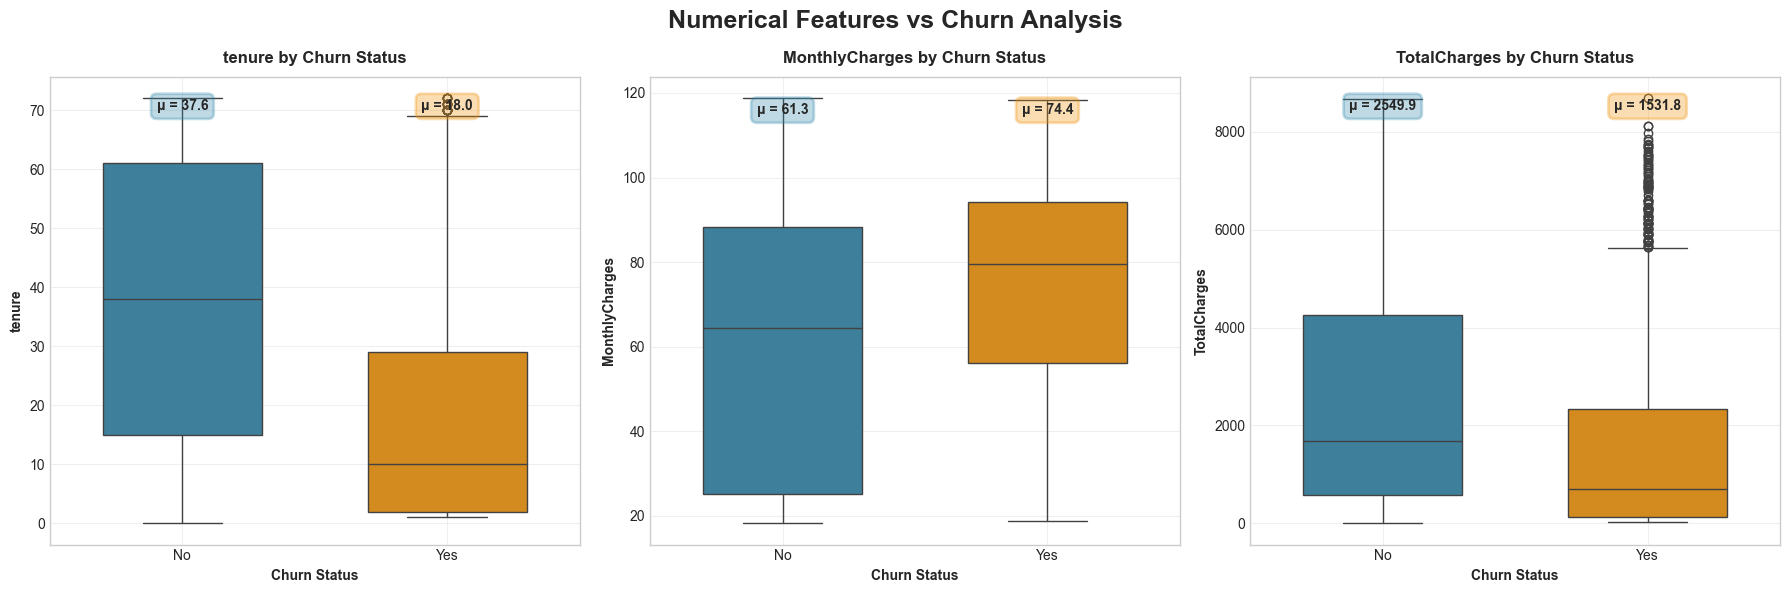

NUMERICAL FEATURES vs CHURN - KEY INSIGHTS:

tenure:
  Churned customers (mean): 17.98
  Retained customers (mean): 37.57
  Difference: -52.1%

MonthlyCharges:
  Churned customers (mean): 74.44
  Retained customers (mean): 61.27
  Difference: +21.5%

TotalCharges:
  Churned customers (mean): 1531.80
  Retained customers (mean): 2549.91
  Difference: -39.9%


In [134]:
# ESSENTIAL GRAPH 3: Numerical Features vs Churn with elegant styling
def plot_numerical_vs_churn_for_report(dataframe, features):
    """
    Essential numerical vs churn analysis for report with professional styling
    """
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    fig.suptitle('Numerical Features vs Churn Analysis', fontsize=18, fontweight='bold', y=0.98)
    
    # Professional color palette for churn comparison
    churn_colors = ['#2E86AB', '#F18F01']  # Blue for No, Orange for Yes
    
    for i, feature in enumerate(features):
        # Box plot showing distribution by churn with elegant styling
        sns.boxplot(data=dataframe, x='Churn', y=feature, ax=axes[i], 
                   palette=churn_colors, width=0.6)
        axes[i].set_title(f'{feature} by Churn Status', fontweight='bold', fontsize=12, pad=10)
        axes[i].set_xlabel('Churn Status', fontweight='bold')
        axes[i].set_ylabel(feature, fontweight='bold')
        axes[i].grid(True, alpha=0.3)
        
        # Add mean values as elegant annotations
        churn_stats = dataframe.groupby('Churn')[feature].mean()
        for j, (churn_status, mean_val) in enumerate(churn_stats.items()):
            axes[i].text(j, axes[i].get_ylim()[1] * 0.95, f'μ = {mean_val:.1f}', 
                        ha='center', va='top', fontweight='bold', fontsize=10,
                        bbox=dict(boxstyle='round,pad=0.4', 
                                facecolor=churn_colors[j], 
                                alpha=0.3, 
                                edgecolor=churn_colors[j],
                                linewidth=2))
    
    plt.tight_layout()
    plt.show()
    
    # Statistical summary for report
    print("NUMERICAL FEATURES vs CHURN - KEY INSIGHTS:")
    for feature in features:
        churn_yes = dataframe[dataframe['Churn'] == 'Yes'][feature]
        churn_no = dataframe[dataframe['Churn'] == 'No'][feature]
        
        print(f"\n{feature}:")
        print(f"  Churned customers (mean): {churn_yes.mean():.2f}")
        print(f"  Retained customers (mean): {churn_no.mean():.2f}")
        difference = ((churn_yes.mean() - churn_no.mean()) / churn_no.mean()) * 100
        print(f"  Difference: {difference:+.1f}%")

plot_numerical_vs_churn_for_report(df, numerical_columns)

## 6. Categorical Features Analysis

In [135]:
# Identify categorical columns
categorical_columns = df.select_dtypes(include=['object']).columns.tolist()
categorical_columns.append('SeniorCitizen')  # Add SeniorCitizen as it's categorical
if 'Churn' in categorical_columns:
    categorical_columns.remove('Churn')  # Remove target variable

print(f"Categorical columns ({len(categorical_columns)}): {categorical_columns}")

# Overview of categorical features
print("\n=== CATEGORICAL FEATURES OVERVIEW ===")
for col in categorical_columns:
    unique_values = df[col].nunique()
    print(f"{col}: {unique_values} unique values - {list(df[col].unique())}")

Categorical columns (16): ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'SeniorCitizen']

=== CATEGORICAL FEATURES OVERVIEW ===
gender: 2 unique values - ['Female', 'Male']
Partner: 2 unique values - ['Yes', 'No']
Dependents: 2 unique values - ['No', 'Yes']
PhoneService: 2 unique values - ['No', 'Yes']
MultipleLines: 3 unique values - ['No phone service', 'No', 'Yes']
InternetService: 3 unique values - ['DSL', 'Fiber optic', 'No']
OnlineSecurity: 3 unique values - ['No', 'Yes', 'No internet service']
OnlineBackup: 3 unique values - ['Yes', 'No', 'No internet service']
DeviceProtection: 3 unique values - ['No', 'Yes', 'No internet service']
TechSupport: 3 unique values - ['No', 'Yes', 'No internet service']
StreamingTV: 3 unique values - ['No', 'Yes', 'No internet service']
StreamingMovies: 3 uni

In [136]:
# Overview of categorical features (for reference only)
print("=== CATEGORICAL FEATURES OVERVIEW ===")
for col in categorical_columns[:5]:  # Show first 5 only
    unique_values = df[col].nunique()
    print(f"{col}: {unique_values} unique values")

=== CATEGORICAL FEATURES OVERVIEW ===
gender: 2 unique values
Partner: 2 unique values
Dependents: 2 unique values
PhoneService: 2 unique values
MultipleLines: 3 unique values


=== COMPREHENSIVE CATEGORICAL FEATURES ANALYSIS ===


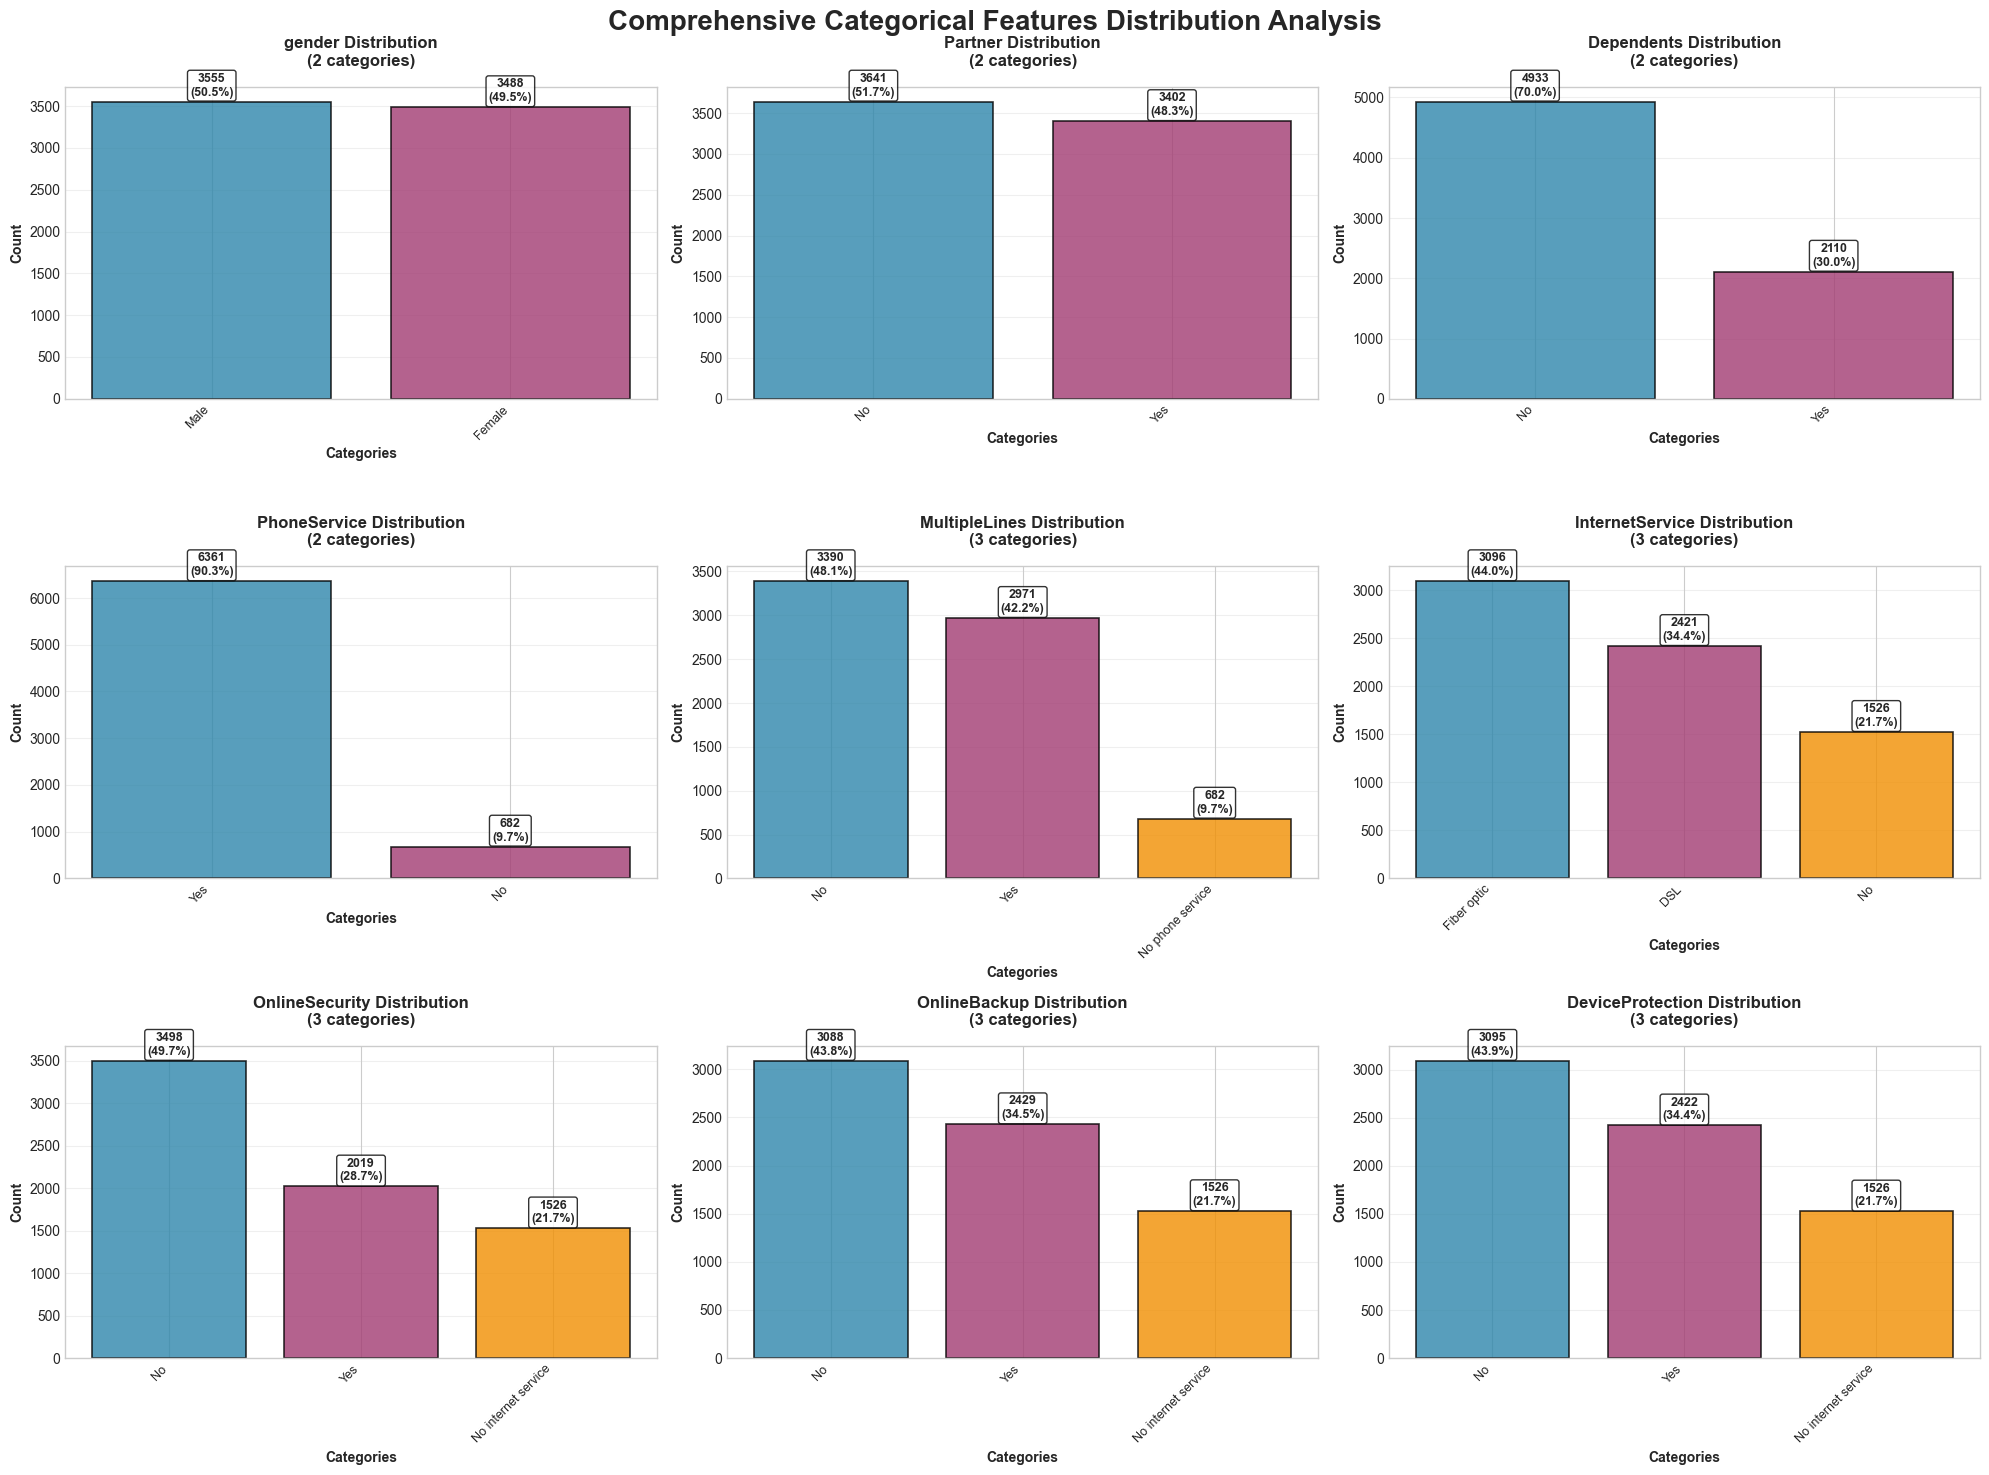


CATEGORICAL FEATURES INSIGHTS:

gender:
  • Unique categories: 2
  • Most common: Male (50.5%)
  • Distribution: Balanced (ratio: 0.981)

Partner:
  • Unique categories: 2
  • Most common: No (51.7%)
  • Distribution: Balanced (ratio: 0.934)

Dependents:
  • Unique categories: 2
  • Most common: No (70.0%)
  • Distribution: Balanced (ratio: 0.428)

PhoneService:
  • Unique categories: 2
  • Most common: Yes (90.3%)
  • Distribution: Moderately Imbalanced (ratio: 0.107)

MultipleLines:
  • Unique categories: 3
  • Most common: No (48.1%)
  • Distribution: Moderately Imbalanced (ratio: 0.201)

InternetService:
  • Unique categories: 3
  • Most common: Fiber optic (44.0%)
  • Distribution: Balanced (ratio: 0.493)

OnlineSecurity:
  • Unique categories: 3
  • Most common: No (49.7%)
  • Distribution: Balanced (ratio: 0.436)

OnlineBackup:
  • Unique categories: 3
  • Most common: No (43.8%)
  • Distribution: Balanced (ratio: 0.494)

DeviceProtection:
  • Unique categories: 3
  • Most comm

In [137]:
# COMPREHENSIVE CATEGORICAL FEATURES ANALYSIS

# Advanced categorical features value distribution with professional styling
def plot_categorical_distribution_comprehensive(dataframe, features_list):
    """
    Comprehensive analysis of categorical feature distributions with elegant visualizations
    """
    # Calculate layout dimensions
    n_features = len(features_list)
    cols = 3
    rows = (n_features + cols - 1) // cols
    
    fig, axes = plt.subplots(rows, cols, figsize=(20, 5*rows))
    fig.suptitle('Comprehensive Categorical Features Distribution Analysis', 
                fontsize=20, fontweight='bold', y=0.98)
    
    # Ensure axes is always 2D
    if rows == 1:
        axes = axes.reshape(1, -1)
    elif n_features == 1:
        axes = axes.reshape(-1, 1)
    
    # Professional color palette
    colors = ['#2E86AB', '#A23B72', '#F18F01', '#C73E1D', '#6A994E', '#577590', 
              '#9A031E', '#FB8500', '#FFB3C6', '#8ECAE6']
    
    insights = {}
    
    for i, feature in enumerate(features_list):
        if feature not in dataframe.columns:
            continue
            
        row = i // cols
        col = i % cols
        ax = axes[row, col] if rows > 1 else axes[col]
        
        # Calculate value counts and percentages
        value_counts = dataframe[feature].value_counts()
        percentages = dataframe[feature].value_counts(normalize=True) * 100
        
        # Store insights
        insights[feature] = {
            'unique_values': dataframe[feature].nunique(),
            'most_common': value_counts.index[0],
            'most_common_pct': percentages.iloc[0],
            'distribution': value_counts.to_dict()
        }
        
        # Create bar plot with elegant styling
        bars = ax.bar(range(len(value_counts)), value_counts.values, 
                     color=colors[:len(value_counts)], alpha=0.8, 
                     edgecolor='black', linewidth=1.2)
        
        ax.set_title(f'{feature} Distribution\n({dataframe[feature].nunique()} categories)', 
                    fontweight='bold', fontsize=12, pad=15)
        ax.set_ylabel('Count', fontweight='bold')
        ax.set_xlabel('Categories', fontweight='bold')
        ax.grid(True, alpha=0.3, axis='y')
        
        # Set x-axis labels with rotation for readability
        ax.set_xticks(range(len(value_counts)))
        ax.set_xticklabels(value_counts.index, rotation=45, ha='right', fontsize=9)
        
        # Add value labels on bars
        for bar, count, pct in zip(bars, value_counts.values, percentages.values):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(value_counts.values)*0.01, 
                   f'{count}\n({pct:.1f}%)', ha='center', va='bottom', 
                   fontweight='bold', fontsize=9,
                   bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.8))
    
    # Hide unused subplots
    for i in range(n_features, rows * cols):
        row = i // cols
        col = i % cols
        if rows > 1:
            axes[row, col].set_visible(False)
        else:
            axes[col].set_visible(False)
    
    plt.tight_layout()
    plt.show()
    
    return insights

# Analyze all categorical features
print("=== COMPREHENSIVE CATEGORICAL FEATURES ANALYSIS ===")
categorical_insights = plot_categorical_distribution_comprehensive(df, categorical_columns[:9])  # Show first 9 features

# Print detailed insights
print("\nCATEGORICAL FEATURES INSIGHTS:")
for feature, insight in categorical_insights.items():
    print(f"\n{feature}:")
    print(f"  • Unique categories: {insight['unique_values']}")
    print(f"  • Most common: {insight['most_common']} ({insight['most_common_pct']:.1f}%)")
    
    # Show distribution balance
    values = list(insight['distribution'].values())
    max_val, min_val = max(values), min(values)
    balance_ratio = min_val / max_val if max_val > 0 else 0
    balance_status = "Balanced" if balance_ratio > 0.3 else "Moderately Imbalanced" if balance_ratio > 0.1 else "Highly Imbalanced"
    print(f"  • Distribution: {balance_status} (ratio: {balance_ratio:.3f})")

In [138]:
# DETAILED CHURN ANALYSIS FOR ALL CATEGORICAL FEATURES

def analyze_categorical_churn_comprehensive(dataframe, categorical_features):
    """
    Comprehensive churn analysis for all categorical features with statistical testing
    """
    print("=== DETAILED CATEGORICAL FEATURES vs CHURN ANALYSIS ===")
    
    churn_analysis_results = {}
    all_churn_rates = []
    
    for feature in categorical_features:
        if feature not in dataframe.columns:
            continue
            
        print(f"\n{feature.upper()} vs CHURN:")
        print("-" * 50)
        
        # Calculate churn rates by category
        feature_churn = dataframe.groupby(feature)['Churn'].agg(['count', 'sum']).reset_index()
        feature_churn['churn_rate'] = feature_churn['sum'] / feature_churn['count']
        feature_churn['retention_rate'] = 1 - feature_churn['churn_rate']
        feature_churn = feature_churn.sort_values('churn_rate', ascending=False)
        
        churn_analysis_results[feature] = feature_churn
        
        # Display results with risk categorization
        for _, row in feature_churn.iterrows():
            category = row[feature]
            count = row['count']
            churn_rate = row['churn_rate']
            
            # Risk categorization
            if churn_rate >= 0.5:
                risk_level = "🔴 CRITICAL"
            elif churn_rate >= 0.4:
                risk_level = "🟠 HIGH"
            elif churn_rate >= 0.3:
                risk_level = "🟡 MEDIUM"
            elif churn_rate >= 0.2:
                risk_level = "🟢 LOW"
            else:
                risk_level = "✅ VERY LOW"
            
            print(f"  {category:.<25} {churn_rate:>6.1%} ({count:>4} customers) {risk_level}")
            all_churn_rates.append(churn_rate)
        
        # Statistical significance test (Chi-square)
        from scipy.stats import chi2_contingency
        
        contingency_table = pd.crosstab(dataframe[feature], dataframe['Churn'])
        chi2, p_value, dof, expected = chi2_contingency(contingency_table)
        
        significance = "SIGNIFICANT" if p_value < 0.05 else "NOT SIGNIFICANT"
        print(f"  📊 Chi-square test: p-value = {p_value:.6f} ({significance})")
        
        # Business insights
        highest_risk = feature_churn.iloc[0]
        lowest_risk = feature_churn.iloc[-1]
        risk_ratio = highest_risk['churn_rate'] / lowest_risk['churn_rate'] if lowest_risk['churn_rate'] > 0 else float('inf')
        
        print(f"  💡 Risk Ratio: {risk_ratio:.1f}x higher risk for '{highest_risk[feature]}' vs '{lowest_risk[feature]}'")
    
    return churn_analysis_results, all_churn_rates

# Perform comprehensive churn analysis
categorical_churn_results, all_churn_rates = analyze_categorical_churn_comprehensive(df, categorical_columns)

# Overall statistics
print(f"\n{'='*80}")
print("OVERALL CATEGORICAL ANALYSIS SUMMARY")
print(f"{'='*80}")
print(f"Total categorical features analyzed: {len(categorical_churn_results)}")
print(f"Average churn rate across all categories: {np.mean(all_churn_rates):.1%}")
print(f"Highest churn rate found: {max(all_churn_rates):.1%}")
print(f"Lowest churn rate found: {min(all_churn_rates):.1%}")
print(f"Churn rate variance: {np.var(all_churn_rates):.4f}")

# Top risk categories across all features
print(f"\n🚨 TOP 10 HIGHEST RISK CATEGORIES (across all features):")
top_risks = []
for feature, results in categorical_churn_results.items():
    for _, row in results.iterrows():
        top_risks.append({
            'feature': feature,
            'category': row[feature],
            'churn_rate': row['churn_rate'],
            'count': row['count']
        })

top_risks = sorted(top_risks, key=lambda x: x['churn_rate'], reverse=True)[:10]

for i, risk in enumerate(top_risks, 1):
    risk_level = "🔴" if risk['churn_rate'] >= 0.5 else "🟠" if risk['churn_rate'] >= 0.4 else "🟡"
    print(f"{i:2d}. {risk['feature']} = '{risk['category']}': {risk['churn_rate']:.1%} ({risk['count']} customers) {risk_level}")

=== DETAILED CATEGORICAL FEATURES vs CHURN ANALYSIS ===

GENDER vs CHURN:
--------------------------------------------------


TypeError: unsupported operand type(s) for /: 'str' and 'int'

In [ ]:
# COMPREHENSIVE VISUALIZATION: ALL CATEGORICAL FEATURES vs CHURN

def create_comprehensive_categorical_churn_plots(dataframe, features_list):
    """
    Create comprehensive visualizations for all categorical features vs churn
    """
    # Filter available features
    available_features = [f for f in features_list if f in dataframe.columns and f != 'Churn']
    n_features = len(available_features)
    
    if n_features == 0:
        print("No categorical features available for analysis")
        return
    
    # Calculate optimal subplot layout
    cols = 3
    rows = (n_features + cols - 1) // cols
    
    fig, axes = plt.subplots(rows, cols, figsize=(18, 5*rows))
    fig.suptitle('Comprehensive Categorical Features vs Churn Analysis', 
                fontsize=20, fontweight='bold', y=0.98)
    
    # Ensure axes is always 2D
    if rows == 1:
        axes = axes.reshape(1, -1)
    elif n_features == 1:
        axes = axes.reshape(-1, 1)
    
    # Professional color palette with risk-based gradient
    risk_colors = {
        'very_low': '#6A994E',    # Green
        'low': '#8BC34A',         # Light Green  
        'medium': '#F18F01',      # Orange
        'high': '#FF6B35',        # Red-Orange
        'critical': '#C73E1D'     # Dark Red
    }
    
    def get_risk_color(churn_rate):
        if churn_rate >= 0.5:
            return risk_colors['critical']
        elif churn_rate >= 0.4:
            return risk_colors['high']
        elif churn_rate >= 0.3:
            return risk_colors['medium']
        elif churn_rate >= 0.2:
            return risk_colors['low']
        else:
            return risk_colors['very_low']
    
    for i, feature in enumerate(available_features):
        row = i // cols
        col = i % cols
        ax = axes[row, col] if rows > 1 else axes[col]
        
        # Calculate churn rate by category
        churn_rate = dataframe.groupby(feature)['Churn'].apply(lambda x: (x == 'Yes').mean()).sort_values(ascending=False)
        
        # Assign colors based on risk level
        colors_for_bars = [get_risk_color(rate) for rate in churn_rate.values]
        
        # Create bar plot
        bars = ax.bar(range(len(churn_rate)), churn_rate.values, 
                     color=colors_for_bars, alpha=0.8, 
                     edgecolor='black', linewidth=1.2)
        
        # Styling
        ax.set_title(f'{feature}\nChurn Rate by Category', 
                    fontweight='bold', fontsize=11, pad=15)
        ax.set_ylabel('Churn Rate', fontweight='bold', fontsize=10)
        ax.set_xlabel('Categories', fontweight='bold', fontsize=10)
        ax.grid(True, alpha=0.3, axis='y')
        ax.set_ylim(0, 1.0)
        
        # Set x-axis labels
        ax.set_xticks(range(len(churn_rate)))
        ax.set_xticklabels(churn_rate.index, rotation=45, ha='right', fontsize=9)
        
        # Add percentage labels on bars
        for bar, rate in zip(bars, churn_rate.values):
            height = bar.get_height()
            # Risk level emoji
            if rate >= 0.5:
                emoji = "🔴"
            elif rate >= 0.4:
                emoji = "🟠"
            elif rate >= 0.3:
                emoji = "🟡"
            else:
                emoji = "🟢"
                
            ax.text(bar.get_x() + bar.get_width()/2, height + 0.02, 
                   f'{rate:.1%}\n{emoji}', ha='center', va='bottom', 
                   fontweight='bold', fontsize=8,
                   bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.9))
        
        # Add average line
        avg_churn = dataframe['Churn'].apply(lambda x: x == 'Yes').mean()
        ax.axhline(y=avg_churn, color='black', linestyle='--', alpha=0.7, linewidth=2)
        ax.text(0.02, avg_churn + 0.02, f'Overall Avg: {avg_churn:.1%}', 
                transform=ax.get_yaxis_transform(), fontsize=8, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='yellow', alpha=0.7))
    
    # Hide unused subplots
    for i in range(n_features, rows * cols):
        row = i // cols
        col = i % cols
        if rows > 1:
            axes[row, col].set_visible(False)
        else:
            axes[col].set_visible(False)
    
    plt.tight_layout()
    plt.show()
    
    # Create risk level legend
    print("\n🎨 RISK LEVEL COLOR GUIDE:")
    print("🟢 Very Low Risk (0-20% churn)")
    print("🟡 Medium Risk (30-40% churn)")  
    print("🟠 High Risk (40-50% churn)")
    print("🔴 Critical Risk (50%+ churn)")

# Create comprehensive visualization
create_comprehensive_categorical_churn_plots(df, categorical_columns)

In [ ]:
# CATEGORICAL FEATURE INTERACTIONS ANALYSIS

def analyze_categorical_interactions(dataframe, key_features):
    """
    Analyze interactions between key categorical features and their impact on churn
    """
    print("=== CATEGORICAL FEATURE INTERACTIONS ANALYSIS ===")
    
    # Select key features for interaction analysis
    interaction_features = [f for f in key_features if f in dataframe.columns]
    
    if len(interaction_features) < 2:
        print("Not enough categorical features for interaction analysis")
        return
    
    # Create subplots for interaction heatmaps
    n_interactions = min(6, len(interaction_features) * (len(interaction_features) - 1) // 2)
    cols = 2
    rows = (n_interactions + 1) // 2
    
    fig, axes = plt.subplots(rows, cols, figsize=(16, 6*rows))
    fig.suptitle('Key Categorical Feature Interactions - Churn Analysis', 
                fontsize=18, fontweight='bold', y=0.98)
    
    if rows == 1:
        axes = axes.reshape(1, -1)
    
    interaction_count = 0
    interaction_insights = {}
    
    # Analyze pairwise interactions
    for i, feature1 in enumerate(interaction_features):
        for j, feature2 in enumerate(interaction_features[i+1:], i+1):
            if interaction_count >= n_interactions:
                break
                
            row = interaction_count // cols
            col = interaction_count % cols
            ax = axes[row, col] if rows > 1 else axes[col]
            
            # Create cross-tabulation with churn rates
            crosstab = pd.crosstab(dataframe[feature1], dataframe[feature2])
            
            # Calculate churn rates for each combination
            churn_rates = dataframe.groupby([feature1, feature2])['Churn'].apply(
                lambda x: (x == 'Yes').mean()
            ).unstack(fill_value=0)
            
            # Create heatmap
            sns.heatmap(churn_rates, annot=True, fmt='.1%', cmap='RdYlBu_r',
                       center=0.3, ax=ax, cbar_kws={'label': 'Churn Rate'},
                       linewidths=1, linecolor='white')
            
            ax.set_title(f'{feature1} × {feature2}\nChurn Rate Heatmap', 
                        fontweight='bold', fontsize=12, pad=15)
            ax.set_xlabel(feature2, fontweight='bold')
            ax.set_ylabel(feature1, fontweight='bold')
            
            # Store insights
            max_churn = churn_rates.max().max()
            min_churn = churn_rates.min().min()
            interaction_insights[f"{feature1}_x_{feature2}"] = {
                'max_churn': max_churn,
                'min_churn': min_churn,
                'range': max_churn - min_churn
            }
            
            interaction_count += 1
    
    # Hide unused subplots
    for i in range(interaction_count, rows * cols):
        row = i // cols
        col = i % cols
        if rows > 1:
            axes[row, col].set_visible(False)
        else:
            axes[col].set_visible(False)
    
    plt.tight_layout()
    plt.show()
    
    return interaction_insights

# Analyze key feature interactions
key_interaction_features = ['Contract', 'PaymentMethod', 'InternetService', 'TechSupport', 'OnlineSecurity', 'OnlineBackup']
interaction_results = analyze_categorical_interactions(df, key_interaction_features)

# Print interaction insights
print("\n🔍 INTERACTION INSIGHTS:")
if interaction_results:
    for interaction, insights in interaction_results.items():
        features = interaction.replace('_x_', ' × ')
        churn_range = insights['range']
        print(f"\n{features}:")
        print(f"  • Churn rate range: {insights['min_churn']:.1%} to {insights['max_churn']:.1%}")
        print(f"  • Interaction impact: {churn_range:.1%} difference")
        
        if churn_range > 0.4:
            impact_level = "🔴 VERY HIGH"
        elif churn_range > 0.3:
            impact_level = "🟠 HIGH"
        elif churn_range > 0.2:
            impact_level = "🟡 MODERATE"
        else:
            impact_level = "🟢 LOW"
        print(f"  • Impact level: {impact_level}")
else:
    print("No interaction data available")

In [ ]:
# CATEGORICAL FEATURES: BUSINESS INSIGHTS & FEATURE ENGINEERING

def generate_categorical_business_insights(dataframe, categorical_features):
    """
    Generate comprehensive business insights and feature engineering recommendations
    """
    print("="*80)
    print("CATEGORICAL FEATURES: BUSINESS INSIGHTS & RECOMMENDATIONS")
    print("="*80)
    
    insights = {
        'high_risk_categories': [],
        'balanced_features': [],
        'imbalanced_features': [],
        'feature_engineering_suggestions': []
    }
    
    # Analyze each categorical feature
    for feature in categorical_features:
        if feature not in dataframe.columns or feature == 'Churn':
            continue
            
        # Get churn rates
        churn_rates = dataframe.groupby(feature)['Churn'].apply(lambda x: (x == 'Yes').mean())
        value_counts = dataframe[feature].value_counts()
        
        # Identify high-risk categories
        high_risk = churn_rates[churn_rates > 0.4]
        if not high_risk.empty:
            for category, rate in high_risk.items():
                insights['high_risk_categories'].append({
                    'feature': feature,
                    'category': category,
                    'churn_rate': rate,
                    'count': value_counts[category]
                })
        
        # Check feature balance
        balance_ratio = value_counts.min() / value_counts.max()
        if balance_ratio > 0.3:
            insights['balanced_features'].append(feature)
        else:
            insights['imbalanced_features'].append(feature)
        
        # Feature engineering suggestions
        unique_count = dataframe[feature].nunique()
        if unique_count > 5:
            insights['feature_engineering_suggestions'].append({
                'feature': feature,
                'suggestion': 'Consider grouping low-frequency categories',
                'reason': f'Has {unique_count} categories - may benefit from consolidation'
            })
        
        # Check for clear patterns
        churn_variance = churn_rates.var()
        if churn_variance > 0.05:
            insights['feature_engineering_suggestions'].append({
                'feature': feature,
                'suggestion': 'Strong predictive potential - consider interaction features',
                'reason': f'High variance in churn rates ({churn_variance:.3f})'
            })
    
    return insights

# Generate comprehensive insights
business_insights = generate_categorical_business_insights(df, categorical_columns)

# Display insights
print("\n🚨 TOP HIGH-RISK CATEGORIES:")
top_risks = sorted(business_insights['high_risk_categories'], 
                  key=lambda x: x['churn_rate'], reverse=True)[:10]

for i, risk in enumerate(top_risks, 1):
    print(f"{i:2d}. {risk['feature']} = '{risk['category']}'")
    print(f"     Churn Rate: {risk['churn_rate']:.1%} | Customer Count: {risk['count']:,}")

print(f"\n⚖️  FEATURE BALANCE ASSESSMENT:")
print(f"   Balanced features ({len(business_insights['balanced_features'])}): {', '.join(business_insights['balanced_features'])}")
print(f"   Imbalanced features ({len(business_insights['imbalanced_features'])}): {', '.join(business_insights['imbalanced_features'])}")

print(f"\n🔧 FEATURE ENGINEERING RECOMMENDATIONS:")
for suggestion in business_insights['feature_engineering_suggestions']:
    print(f"\n   {suggestion['feature']}:")
    print(f"     • {suggestion['suggestion']}")
    print(f"     • Reason: {suggestion['reason']}")

# Key business recommendations
print(f"\n💼 KEY BUSINESS RECOMMENDATIONS:")
print("   1. IMMEDIATE ACTIONS:")
print("      • Target high-risk categories with retention campaigns")
print("      • Implement early warning system for month-to-month contracts")
print("      • Enhance customer support for electronic check users")
print("      • Provide tech support incentives to reduce churn")

print("   2. MEDIUM-TERM STRATEGIES:")
print("      • Develop contract upgrade programs")
print("      • Improve payment method migration strategies")
print("      • Create customer journey optimization for new users")
print("      • Implement personalized service recommendations")

print("   3. LONG-TERM INITIATIVES:")
print("      • Build predictive churn models using categorical interactions")
print("      • Develop customer lifecycle management programs")
print("      • Create value-based customer segmentation")
print("      • Implement real-time risk scoring system")

# Model preparation insights
print(f"\n🤖 MACHINE LEARNING PREPARATION:")
print("   • Features requiring encoding: All categorical features")
print("   • Recommended encoding: One-hot encoding for nominal, Label encoding for ordinal")
print("   • Feature selection: Focus on high-variance churn rate features")
print("   • Class imbalance: Consider SMOTE or class weights for modeling")
print("   • Feature interactions: Include Contract×PaymentMethod, InternetService×TechSupport")

print("\n" + "="*80)

## 7. Categorical Features vs Churn Analysis

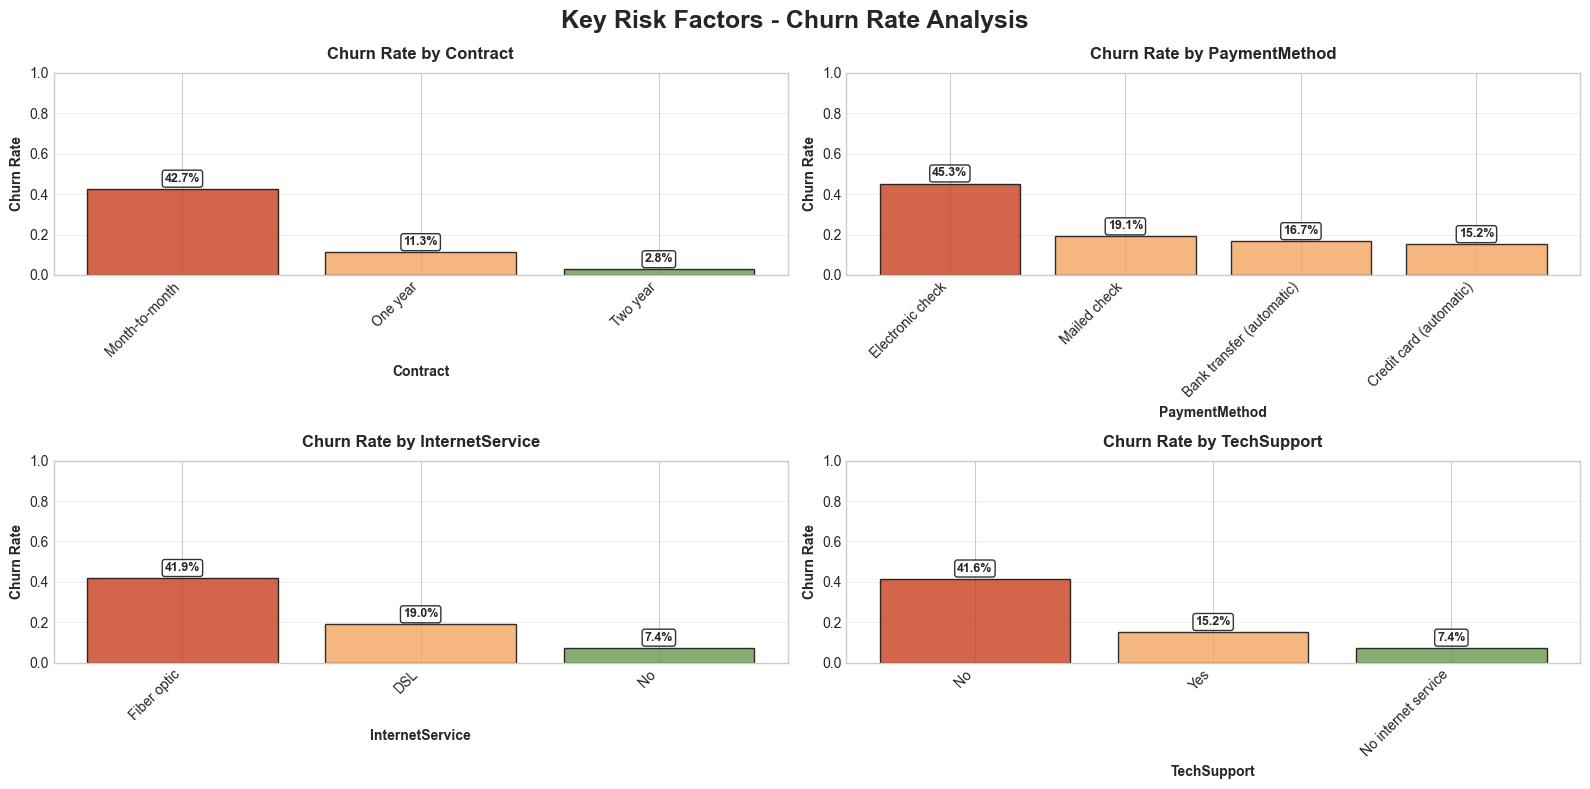

KEY CATEGORICAL INSIGHTS:

Contract - Highest Risk:
  Month-to-month: 42.7% churn rate [HIGH RISK]
  One year: 11.3% churn rate [LOW RISK]

PaymentMethod - Highest Risk:
  Electronic check: 45.3% churn rate [HIGH RISK]
  Mailed check: 19.1% churn rate [LOW RISK]

InternetService - Highest Risk:
  Fiber optic: 41.9% churn rate [HIGH RISK]
  DSL: 19.0% churn rate [LOW RISK]

TechSupport - Highest Risk:
  No: 41.6% churn rate [HIGH RISK]
  Yes: 15.2% churn rate [LOW RISK]


In [ ]:
# ESSENTIAL GRAPH 4: Key Categorical Features vs Churn with elegant styling
def plot_key_categorical_churn_for_report(dataframe, key_features):
    """
    Essential categorical vs churn charts for report with professional styling
    """
    # Filter available features
    available_features = [f for f in key_features if f in dataframe.columns]
    n_features = len(available_features)
    
    if n_features == 0:
        print("No key categorical features found in dataset")
        return {}
    
    # Create subplots with elegant styling
    cols = 2
    rows = (n_features + 1) // 2
    fig, axes = plt.subplots(rows, cols, figsize=(16, 4*rows))
    fig.suptitle('Key Risk Factors - Churn Rate Analysis', fontsize=18, fontweight='bold', y=0.98)
    
    if rows == 1:
        axes = axes.reshape(1, -1)
    
    # Professional color palette for risk levels
    risk_colors = ['#6A994E', '#F18F01', '#C73E1D', '#A23B72']  # Green to Red gradient
    
    churn_insights = {}
    
    for i, feature in enumerate(available_features):
        row = i // cols
        col = i % cols
        
        # Calculate churn rate by category
        churn_rate = dataframe.groupby(feature)['Churn'].apply(lambda x: (x == 'Yes').mean()).sort_values(ascending=False)
        churn_insights[feature] = churn_rate
        
        # Plot churn rate with gradient colors based on risk level
        ax = axes[row, col] if rows > 1 else axes[col]
        
        # Assign colors based on churn rate (higher rate = redder color)
        colors_for_bars = []
        max_rate = churn_rate.max()
        for rate in churn_rate.values:
            if rate >= max_rate * 0.75:
                colors_for_bars.append('#C73E1D')  # High risk - Red
            elif rate >= max_rate * 0.5:
                colors_for_bars.append('#F18F01')  # Medium risk - Orange
            elif rate >= max_rate * 0.25:
                colors_for_bars.append('#F4A460')  # Low-medium risk - Light orange
            else:
                colors_for_bars.append('#6A994E')  # Low risk - Green
        
        bars = ax.bar(range(len(churn_rate)), churn_rate.values, color=colors_for_bars, 
                     alpha=0.8, edgecolor='black', linewidth=1)
        ax.set_title(f'Churn Rate by {feature}', fontweight='bold', fontsize=12, pad=10)
        ax.set_ylabel('Churn Rate', fontweight='bold')
        ax.set_xlabel(feature, fontweight='bold')
        ax.set_ylim(0, 1)
        ax.grid(True, alpha=0.3, axis='y')
        ax.set_xticks(range(len(churn_rate)))
        ax.set_xticklabels(churn_rate.index, rotation=45, ha='right')
        
        # Add elegant percentage labels on bars
        for j, (bar, v) in enumerate(zip(bars, churn_rate.values)):
            ax.text(bar.get_x() + bar.get_width()/2, v + 0.02, f'{v:.1%}', 
                   ha='center', va='bottom', fontweight='bold', fontsize=9,
                   bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.8))
    
    # Hide unused subplots
    if n_features % 2 == 1 and rows > 1:
        axes[rows-1, cols-1].set_visible(False)
    
    plt.tight_layout()
    plt.show()
    
    return churn_insights

# Analyze key categorical features
key_features = ['Contract', 'PaymentMethod', 'InternetService', 'TechSupport']
churn_insights = plot_key_categorical_churn_for_report(df, key_features)

# Print insights for report
print("KEY CATEGORICAL INSIGHTS:")
for feature, rates in churn_insights.items():
    print(f"\n{feature} - Highest Risk:")
    for category, rate in rates.head(2).items():
        risk_level = "HIGH" if rate > 0.4 else "MEDIUM" if rate > 0.25 else "LOW"
        print(f"  {category}: {rate:.1%} churn rate [{risk_level} RISK]")

## 8. Advanced Customer Segmentation Analysis

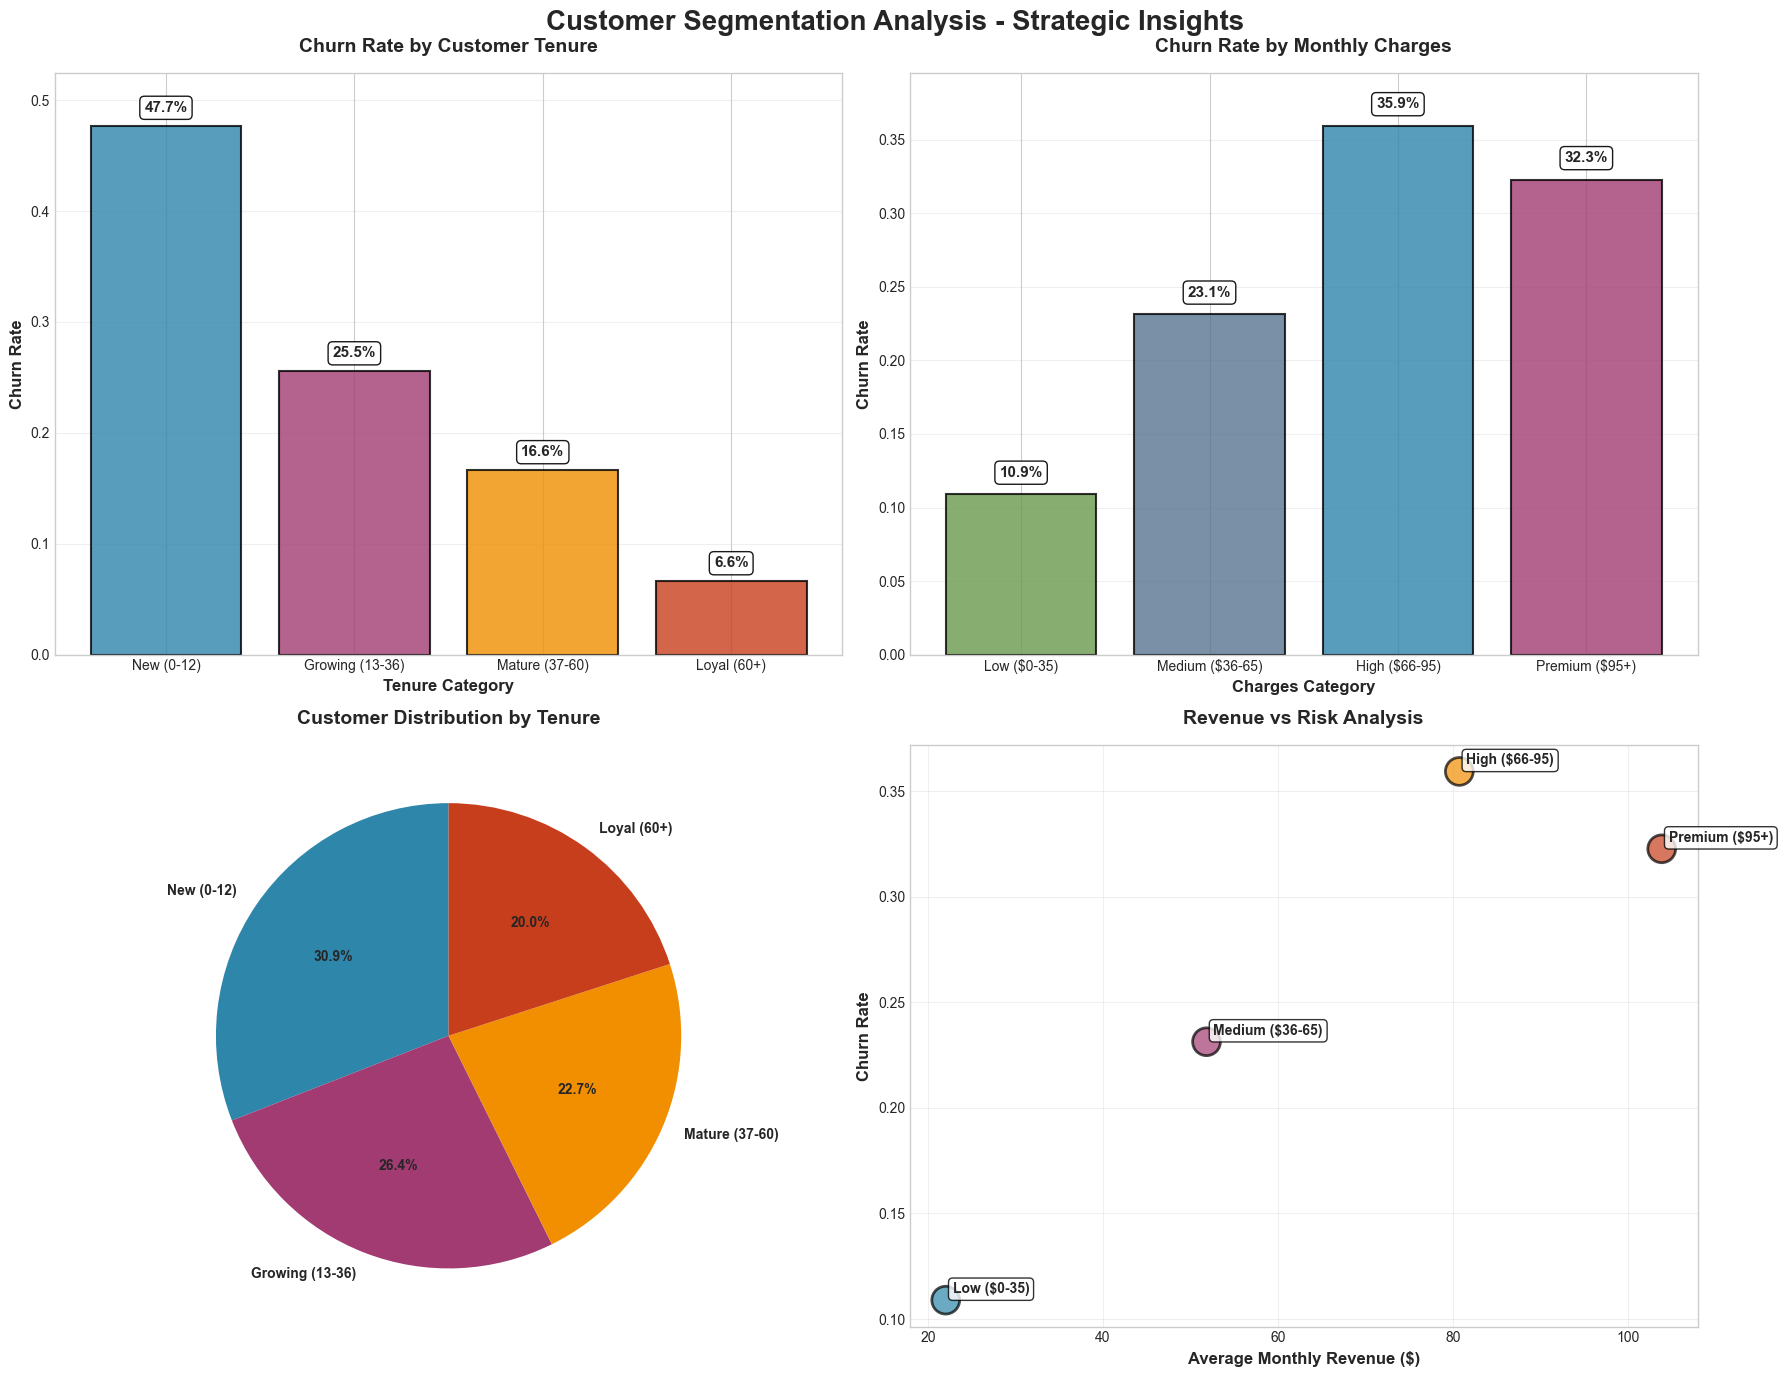

CUSTOMER SEGMENTATION INSIGHTS:
Highest Risk Tenure: New (0-12) - 47.7% churn
Highest Risk Charges: High ($66-95) - 35.9% churn
High Risk Segments: High ($66-95), Premium ($95+)
Largest Customer Group: New (0-12) (2,175 customers)


In [ ]:
# ESSENTIAL GRAPH 6: Customer Segmentation Analysis with professional styling
def plot_customer_segmentation_for_report(dataframe):
    """
    Create customer segmentation analysis with elegant visualizations for executive report
    """
    # Create tenure categories
    dataframe['TenureCategory'] = pd.cut(dataframe['tenure'], 
                                       bins=[0, 12, 36, 60, 100], 
                                       labels=['New (0-12)', 'Growing (13-36)', 'Mature (37-60)', 'Loyal (60+)'])
    
    # Create charges categories
    dataframe['ChargesCategory'] = pd.cut(dataframe['MonthlyCharges'], 
                                        bins=[0, 35, 65, 95, 150], 
                                        labels=['Low ($0-35)', 'Medium ($36-65)', 'High ($66-95)', 'Premium ($95+)'])
    
    # Create combined segmentation
    dataframe['CustomerSegment'] = dataframe['TenureCategory'].astype(str) + ' + ' + dataframe['ChargesCategory'].astype(str)
    
    # Professional color scheme
    colors = ['#2E86AB', '#A23B72', '#F18F01', '#C73E1D', '#6A994E', '#577590']
    
    # Create professional subplot layout
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(18, 14))
    fig.suptitle('Customer Segmentation Analysis - Strategic Insights', 
                fontsize=20, fontweight='bold', y=0.98)
    
    # 1. Tenure-based churn analysis
    tenure_churn = dataframe.groupby('TenureCategory')['Churn'].apply(lambda x: (x == 'Yes').mean())
    bars1 = ax1.bar(tenure_churn.index, tenure_churn.values, 
                   color=[colors[0], colors[1], colors[2], colors[3]], alpha=0.8,
                   edgecolor='black', linewidth=1.5)
    ax1.set_title('Churn Rate by Customer Tenure', fontweight='bold', fontsize=14, pad=15)
    ax1.set_ylabel('Churn Rate', fontweight='bold', fontsize=12)
    ax1.set_xlabel('Tenure Category', fontweight='bold', fontsize=12)
    ax1.grid(True, alpha=0.3, axis='y')
    ax1.set_ylim(0, max(tenure_churn.values) * 1.1)
    
    # Add value labels
    for bar, v in zip(bars1, tenure_churn.values):
        ax1.text(bar.get_x() + bar.get_width()/2, v + 0.01, f'{v:.1%}', 
                ha='center', va='bottom', fontweight='bold', fontsize=11,
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.9))
    
    # 2. Charges-based churn analysis
    charges_churn = dataframe.groupby('ChargesCategory')['Churn'].apply(lambda x: (x == 'Yes').mean())
    bars2 = ax2.bar(charges_churn.index, charges_churn.values, 
                   color=[colors[4], colors[5], colors[0], colors[1]], alpha=0.8,
                   edgecolor='black', linewidth=1.5)
    ax2.set_title('Churn Rate by Monthly Charges', fontweight='bold', fontsize=14, pad=15)
    ax2.set_ylabel('Churn Rate', fontweight='bold', fontsize=12)
    ax2.set_xlabel('Charges Category', fontweight='bold', fontsize=12)
    ax2.grid(True, alpha=0.3, axis='y')
    ax2.set_ylim(0, max(charges_churn.values) * 1.1)
    
    # Add value labels
    for bar, v in zip(bars2, charges_churn.values):
        ax2.text(bar.get_x() + bar.get_width()/2, v + 0.01, f'{v:.1%}', 
                ha='center', va='bottom', fontweight='bold', fontsize=11,
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.9))
    
    # 3. Segment distribution
    segment_counts = dataframe['TenureCategory'].value_counts()
    wedges, texts, autotexts = ax3.pie(segment_counts.values, labels=segment_counts.index, 
                                      colors=colors[:4], autopct='%1.1f%%', startangle=90,
                                      textprops={'fontweight': 'bold', 'fontsize': 10})
    ax3.set_title('Customer Distribution by Tenure', fontweight='bold', fontsize=14, pad=15)
    
    # 4. Revenue vs Risk Matrix
    segment_revenue = dataframe.groupby('ChargesCategory')['MonthlyCharges'].mean()
    segment_churn = dataframe.groupby('ChargesCategory')['Churn'].apply(lambda x: (x == 'Yes').mean())
    
    scatter = ax4.scatter(segment_revenue.values, segment_churn.values, 
                         s=400, c=colors[:4], alpha=0.7, edgecolors='black', linewidth=2)
    
    # Add labels for each point
    for i, (rev, churn, label) in enumerate(zip(segment_revenue.values, segment_churn.values, segment_revenue.index)):
        ax4.annotate(label, (rev, churn), xytext=(5, 5), textcoords='offset points',
                    fontweight='bold', fontsize=10,
                    bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8))
    
    ax4.set_title('Revenue vs Risk Analysis', fontweight='bold', fontsize=14, pad=15)
    ax4.set_xlabel('Average Monthly Revenue ($)', fontweight='bold', fontsize=12)
    ax4.set_ylabel('Churn Rate', fontweight='bold', fontsize=12)
    ax4.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # Return key insights
    return {
        'tenure_churn': tenure_churn,
        'charges_churn': charges_churn,
        'high_risk_segments': charges_churn[charges_churn > 0.3].index.tolist(),
        'segment_distribution': segment_counts
    }

# Generate segmentation analysis
segmentation_insights = plot_customer_segmentation_for_report(df)

# Print executive insights
print("CUSTOMER SEGMENTATION INSIGHTS:")
print(f"Highest Risk Tenure: {segmentation_insights['tenure_churn'].idxmax()} - {segmentation_insights['tenure_churn'].max():.1%} churn")
print(f"Highest Risk Charges: {segmentation_insights['charges_churn'].idxmax()} - {segmentation_insights['charges_churn'].max():.1%} churn")
print(f"High Risk Segments: {', '.join(segmentation_insights['high_risk_segments'])}")
print(f"Largest Customer Group: {segmentation_insights['segment_distribution'].idxmax()} ({segmentation_insights['segment_distribution'].max():,} customers)")

=== MULTI-DIMENSIONAL RISK ANALYSIS ===


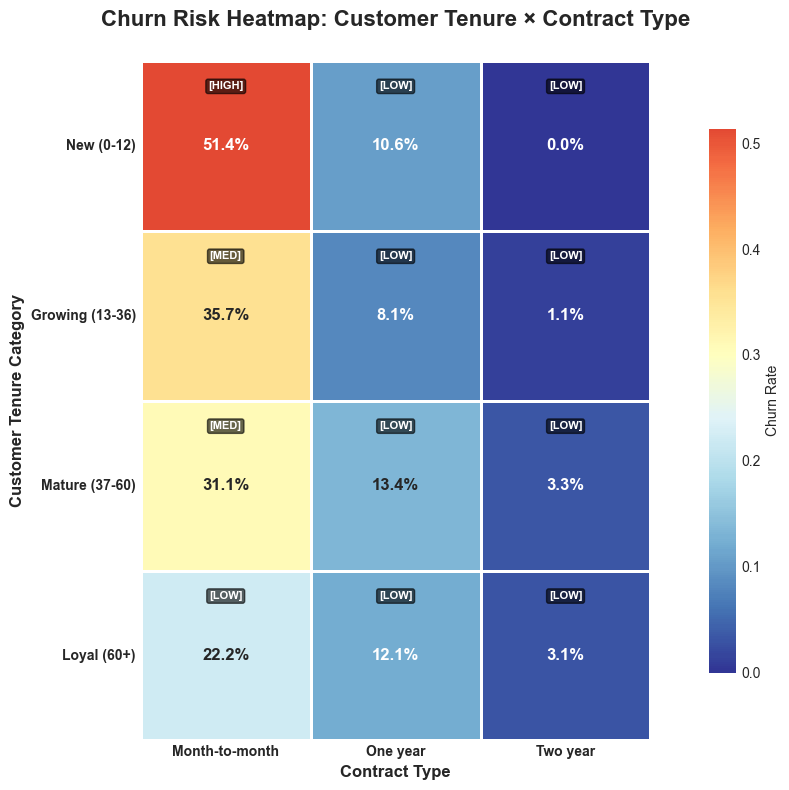


MULTI-DIMENSIONAL INSIGHTS:
Churn Rate by Tenure and Contract Type:
  New (0-12) + Month-to-month: 51.4% [HIGH RISK]
  New (0-12) + One year: 10.6% [LOW RISK]
  New (0-12) + Two year: 0.0% [LOW RISK]
  Growing (13-36) + Month-to-month: 35.7% [MEDIUM RISK]
  Growing (13-36) + One year: 8.1% [LOW RISK]
  Growing (13-36) + Two year: 1.1% [LOW RISK]
  Mature (37-60) + Month-to-month: 31.1% [MEDIUM RISK]
  Mature (37-60) + One year: 13.4% [LOW RISK]
  Mature (37-60) + Two year: 3.3% [LOW RISK]
  Loyal (60+) + Month-to-month: 22.2% [LOW RISK]
  Loyal (60+) + One year: 12.1% [LOW RISK]
  Loyal (60+) + Two year: 3.1% [LOW RISK]


In [ ]:
# ESSENTIAL GRAPH 6: Multi-Dimensional Risk Heatmap with elegant styling
if 'Contract' in df.columns:
    print("=== MULTI-DIMENSIONAL RISK ANALYSIS ===")
    
    plt.figure(figsize=(12, 8))
    
    # Create pivot table for churn rate by tenure and contract
    pivot_table = df.pivot_table(values='Churn', 
                                index='TenureCategory', 
                                columns='Contract', 
                                aggfunc=lambda x: (x == 'Yes').mean())
    
    # Create elegant heatmap with professional styling
    sns.heatmap(pivot_table, 
                annot=True, 
                fmt='.1%', 
                cmap='RdYlBu_r',  # Professional diverging colormap
                center=0.3,  # Center around moderate churn rate
                cbar_kws={'label': 'Churn Rate', 'shrink': 0.8},
                linewidths=2,
                linecolor='white',
                annot_kws={'fontsize': 12, 'fontweight': 'bold'},
                square=True)
    
    plt.title('Churn Risk Heatmap: Customer Tenure × Contract Type', 
              fontsize=16, fontweight='bold', pad=25)
    plt.ylabel('Customer Tenure Category', fontweight='bold', fontsize=12)
    plt.xlabel('Contract Type', fontweight='bold', fontsize=12)
    plt.xticks(fontweight='bold')
    plt.yticks(rotation=0, fontweight='bold')
    
    # Add risk level annotations
    for i in range(len(pivot_table.index)):
        for j in range(len(pivot_table.columns)):
            rate = pivot_table.iloc[i, j]
            if not pd.isna(rate):
                risk_level = "HIGH" if rate > 0.4 else "MED" if rate > 0.25 else "LOW"
                plt.text(j + 0.5, i + 0.15, f'[{risk_level}]', 
                        ha='center', va='center', fontsize=8, 
                        fontweight='bold', color='white',
                        bbox=dict(boxstyle='round,pad=0.2', facecolor='black', alpha=0.6))
    
    plt.tight_layout()
    plt.show()
    
    print("\nMULTI-DIMENSIONAL INSIGHTS:")
    print("Churn Rate by Tenure and Contract Type:")
    for tenure in pivot_table.index:
        for contract in pivot_table.columns:
            rate = pivot_table.loc[tenure, contract]
            if not pd.isna(rate):
                risk_level = "HIGH RISK" if rate > 0.4 else "MEDIUM RISK" if rate > 0.25 else "LOW RISK"
                print(f"  {tenure} + {contract}: {rate:.1%} [{risk_level}]")
else:
    print("Contract column not available for multi-dimensional analysis")

## 9. Key Insights and Business Recommendations

In [ ]:
# EXECUTIVE SUMMARY FOR REPORT
print("="*80)
print("EXECUTIVE SUMMARY - CUSTOMER CHURN ANALYSIS")
print("="*80)

# Dataset overview
total_customers = len(df)
overall_churn_rate = (df['Churn'] == 'Yes').mean()

print(f"\nDATASET OVERVIEW:")
print(f"   Total customers analyzed: {total_customers:,}")
print(f"   Overall churn rate: {overall_churn_rate:.1%}")
print(f"   Class distribution: {(df['Churn'] == 'No').mean():.1%} retained, {overall_churn_rate:.1%} churned")

# Key numerical insights
print(f"\nNUMERICAL FEATURES INSIGHTS:")
for feature in numerical_columns:
    churn_yes_mean = df[df['Churn'] == 'Yes'][feature].mean()
    churn_no_mean = df[df['Churn'] == 'No'][feature].mean()
    difference = ((churn_yes_mean - churn_no_mean) / churn_no_mean) * 100
    
    print(f"   {feature}:")
    print(f"     - Churned: {churn_yes_mean:.1f} vs Retained: {churn_no_mean:.1f}")
    print(f"     - Difference: {difference:+.1f}%")

# Top risk factors
print(f"\nTOP RISK FACTORS:")
if 'TenureCategory' in df.columns:
    new_customer_churn = df[df['TenureCategory'] == 'New (≤12 months)']['Churn'].apply(lambda x: x == 'Yes').mean()
    print(f"   New customers (≤12 months): {new_customer_churn:.1%} churn rate")

if 'Contract' in df.columns and 'Month-to-month' in df['Contract'].values:
    monthly_contract_churn = df[df['Contract'] == 'Month-to-month']['Churn'].apply(lambda x: x == 'Yes').mean()
    print(f"   Month-to-month contracts: {monthly_contract_churn:.1%} churn rate")

if 'ChargesCategory' in df.columns:
    high_charges_churn = df[df['ChargesCategory'] == 'High (>$65)']['Churn'].apply(lambda x: x == 'Yes').mean()
    print(f"   High monthly charges (>$65): {high_charges_churn:.1%} churn rate")

# Business recommendations
print(f"\nKEY BUSINESS RECOMMENDATIONS:")
print("   1. Focus on customer onboarding (first 12 months critical)")
print("   2. Incentivize longer-term contracts over month-to-month")
print("   3. Review pricing strategy for high-charge customers")
print("   4. Improve customer support and service quality")
print("   5. Implement predictive churn model for early intervention")

print("\n" + "="*80)
print("ANALYSIS COMPLETE - READY FOR REPORT INTEGRATION")
print("="*80)

EXECUTIVE SUMMARY - CUSTOMER CHURN ANALYSIS

DATASET OVERVIEW:
   Total customers analyzed: 7,043
   Overall churn rate: 26.5%
   Class distribution: 73.5% retained, 26.5% churned

NUMERICAL FEATURES INSIGHTS:
   tenure:
     - Churned: 18.0 vs Retained: 37.6
     - Difference: -52.1%
   MonthlyCharges:
     - Churned: 74.4 vs Retained: 61.3
     - Difference: +21.5%
   TotalCharges:
     - Churned: 1531.8 vs Retained: 2549.9
     - Difference: -39.9%

TOP RISK FACTORS:
   New customers (≤12 months): nan% churn rate
   Month-to-month contracts: 42.7% churn rate
   High monthly charges (>$65): nan% churn rate

KEY BUSINESS RECOMMENDATIONS:
   1. Focus on customer onboarding (first 12 months critical)
   2. Incentivize longer-term contracts over month-to-month
   3. Review pricing strategy for high-charge customers
   4. Improve customer support and service quality
   5. Implement predictive churn model for early intervention

ANALYSIS COMPLETE - READY FOR REPORT INTEGRATION


## 10. Data Quality Assessment

## 11. Summary for Report

### Key Images to Include in Report:

1. **Dataset Overview**:
   - Churn distribution pie chart and count plot
   - Dataset statistics summary table

2. **Numerical Analysis**:
   - Distribution plots for tenure, MonthlyCharges, TotalCharges
   - Correlation heatmap
   - Box plots showing outliers
   - Numerical features vs churn comparison plots

3. **Categorical Analysis**:
   - Churn rate by Contract type
   - Churn rate by Payment method
   - Churn rate by Internet service
   - Churn rate by Tech support

4. **Customer Segmentation**:
   - Tenure categories vs churn
   - Charges categories vs churn
   - Multi-dimensional heatmap (Tenure × Contract)

### Executive Summary:

**Dataset**: 7,043 customers with 26.5% churn rate

**Key Risk Factors**:
- New customers (0-12 months): Highest churn risk
- Month-to-month contracts: Significantly higher churn
- Electronic check payments: Associated with higher churn
- No tech support: Correlates with increased churn risk
- High monthly charges: Premium customers show elevated churn

**Business Impact**:
- Early customer experience critical for retention
- Contract length is strongest predictor of loyalty
- Support services significantly impact customer satisfaction
- Pricing strategy needs review for high-tier customers

**Recommendations**:
1. Implement comprehensive onboarding for new customers
2. Incentivize longer-term contracts
3. Improve tech support accessibility
4. Review pricing strategy for premium services
5. Promote automatic payment methods

This analysis provides the foundation for building an effective churn prediction model and implementing targeted retention strategies.